# E232 · When does replay help?

**Complete** · E232 finished  
Updated 2026-11-23T12:08:28+01:00 Stockholm

Eight E231 walks supply paired checkpoints. Acquisition starts at the first A → B shift. Retention starts after 96 common incoming-only B updates and returns to disjoint later frames in the A captures. Replay uses a 64-image bank from the most recent prior regime. Each action sustains its ratio for 192 optimizer steps at batch size two and LR 7.5e-5. The +96 readout measures the shorter horizon. All candidates share exact model and optimizer starts. Four mask draws are independent within each walk and shared across candidate actions.

The semantic target is acquisition or preservation of B in the respective state. A-panel effects are shown separately. The leave-one-draw-out oracle ranks actions on the other three masks and scores on the held-out mask. The replay-budget test allows (0%, 50%), (25%, 25%) or (50%, 0%) across the paired states. Each allocation uses the same replay image count and optimizer steps as fixed 25%. The two branches begin from fixed common checkpoints, so the budget comparison estimates matched counterfactual assignment value. Walk intervals condition on the shared semantic keyframe corpus.

The common incoming-only B update changed held-out B accuracy by **+0.952 [+0.104, +1.849] pp**. A retention threat is assessed by the subsequent incoming-only A return from that common B state. States remain in the analysis regardless of earlier acquisition or observed forgetting.

## 96 optimizer updates

| Situation | Strategy | B vs same-state frozen (pp) | A vs same-state frozen (pp) |
| --- | --- | --- | --- |
| Acquisition | 0% replay | +0.898 [+0.015, +1.849] | +0.245 [+0.012, +0.522] |
| Acquisition | 25% replay | +0.456 [-0.135, +1.161] | +0.318 [+0.102, +0.614] |
| Acquisition | 50% replay | +0.299 [-0.156, +0.872] | +0.492 [+0.198, +0.860] |
| Acquisition | No adaptation | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Retention | 0% replay | -0.661 [-1.650, +0.085] | -0.199 [-0.440, +0.003] |
| Retention | 25% replay | -0.268 [-1.100, +0.219] | -0.210 [-0.474, +0.080] |
| Retention | 50% replay | -0.355 [-1.108, +0.117] | -0.147 [-0.471, +0.165] |
| Retention | No adaptation | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |

**50% versus 0% replay interaction (retention minus acquisition)** +0.906 [-0.021, +1.977] pp.

| Oracle comparison | Gain (pp) |
| --- | --- |
| Unconstrained versus 0% replay | +0.305 [+0.097, +0.408] |
| Matched-budget versus fixed 25% | +0.268 [+0.022, +0.573] |
| Matched-budget versus fixed 25%, excluding lighting | +0.081 [+0.009, +0.154] |
| Acquisition oracle versus strongest fixed | +0.165 [+0.032, +0.299] |
| Retention oracle versus strongest fixed | +0.051 [-0.015, +0.117] |

| Retrospective oracle | 0% | 25% | 50% |
| --- | --- | --- | --- |
| Acquisition | 16 | 0 | 16 |
| Retention | 5 | 14 | 13 |

The independently selected action was tied for best within 0.10 pp on **+92.188 [+85.938, +98.438]%** of test draws. Its preferred ratio differed across the two states on **+78.125 [+53.125, +96.875]%** of pairs. The three exact-budget allocations were chosen [10, 9, 13] times in the order above.

| Strategy | Replay exposures | Incoming exposures | Updates | Training s |
| --- | --- | --- | --- | --- |
| 0% replay | 0 | 192 | 96 | 0.879 |
| 25% replay | 48 | 144 | 96 | 0.879 |
| 50% replay | 96 | 96 | 96 | 0.879 |
| No adaptation | 0 | 0 | 0 | 0.000 |

The label-free predictor is a Ridge model for raw functional branch differences fitted on other walks. It uses only 32 observed incoming frames and the past bank at decision time. The training targets combine independent raw-clip reconstruction, augmented retrieval and historical drift. At a fixed replay budget the first decision uses its visible features and a training-walk retention prior. The second decision spends the remainder.

| Selector | Free budget vs strongest fixed (pp) | Replay fraction (%) | Exact budget vs 25% (pp) |
| --- | --- | --- | --- |
| Functional fixed prior | +0.000 [-0.324, +0.000] | 0.0 | — |
| Known-phase benchmark | -0.246 [-0.577, -0.088] | 14.1 | -0.275 [-0.650, +0.034] |
| Causal label-free ridge | -0.263 [-0.624, -0.086] | 18.8 | -0.299 [-0.663, +0.002] |

Causal Ridge action-pair concordance **+39.726 [+21.088, +60.544]%** across 146 comparable predictions.

## 192 optimizer updates

| Situation | Strategy | B vs same-state frozen (pp) | A vs same-state frozen (pp) |
| --- | --- | --- | --- |
| Acquisition | 0% replay | +0.956 [-0.041, +1.963] | +0.210 [-0.004, +0.437] |
| Acquisition | 25% replay | +0.639 [+0.076, +1.383] | +0.398 [+0.189, +0.573] |
| Acquisition | 50% replay | +0.482 [-0.118, +1.293] | +0.551 [+0.318, +0.742] |
| Acquisition | No adaptation | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| Retention | 0% replay | -0.554 [-1.539, +0.237] | -0.306 [-0.457, -0.171] |
| Retention | 25% replay | -0.301 [-1.169, +0.414] | -0.200 [-0.429, +0.071] |
| Retention | 50% replay | -0.233 [-1.184, +0.521] | -0.052 [-0.274, +0.175] |
| Retention | No adaptation | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |

**50% versus 0% replay interaction (retention minus acquisition)** +0.795 [-0.109, +1.793] pp.

| Oracle comparison | Gain (pp) |
| --- | --- |
| Unconstrained versus 0% replay | +0.432 [+0.032, +0.546] |
| Matched-budget versus fixed 25% | +0.290 [+0.073, +0.630] |
| Matched-budget versus fixed 25%, excluding lighting | +0.171 [+0.053, +0.295] |
| Acquisition oracle versus strongest fixed | +0.209 [+0.010, +0.392] |
| Retention oracle versus strongest fixed | +0.334 [+0.008, +0.628] |

| Retrospective oracle | 0% | 25% | 50% |
| --- | --- | --- | --- |
| Acquisition | 14 | 2 | 16 |
| Retention | 6 | 11 | 15 |

The independently selected action was tied for best within 0.10 pp on **+85.938 [+70.312, +95.312]%** of test draws. Its preferred ratio differed across the two states on **+62.500 [+25.000, +87.500]%** of pairs. The three exact-budget allocations were chosen [22, 3, 7] times in the order above.

| Strategy | Replay exposures | Incoming exposures | Updates | Training s |
| --- | --- | --- | --- | --- |
| 0% replay | 0 | 384 | 192 | 1.758 |
| 25% replay | 96 | 288 | 192 | 1.759 |
| 50% replay | 192 | 192 | 192 | 1.759 |
| No adaptation | 0 | 0 | 0 | 0.000 |

The label-free predictor is a Ridge model for raw functional branch differences fitted on other walks. It uses only 32 observed incoming frames and the past bank at decision time. The training targets combine independent raw-clip reconstruction, augmented retrieval and historical drift. At a fixed replay budget the first decision uses its visible features and a training-walk retention prior. The second decision spends the remainder.

| Selector | Free budget vs strongest fixed (pp) | Replay fraction (%) | Exact budget vs 25% (pp) |
| --- | --- | --- | --- |
| Functional fixed prior | -0.077 [-0.905, +0.000] | 50.0 | — |
| Known-phase benchmark | -0.275 [-0.987, -0.073] | 39.1 | -0.187 [-0.674, +0.275] |
| Causal label-free ridge | -0.148 [-0.882, +0.054] | 35.9 | -0.115 [-0.420, +0.097] |

Causal Ridge action-pair concordance **+53.741 [+36.364, +69.784]%** across 147 comparable predictions.

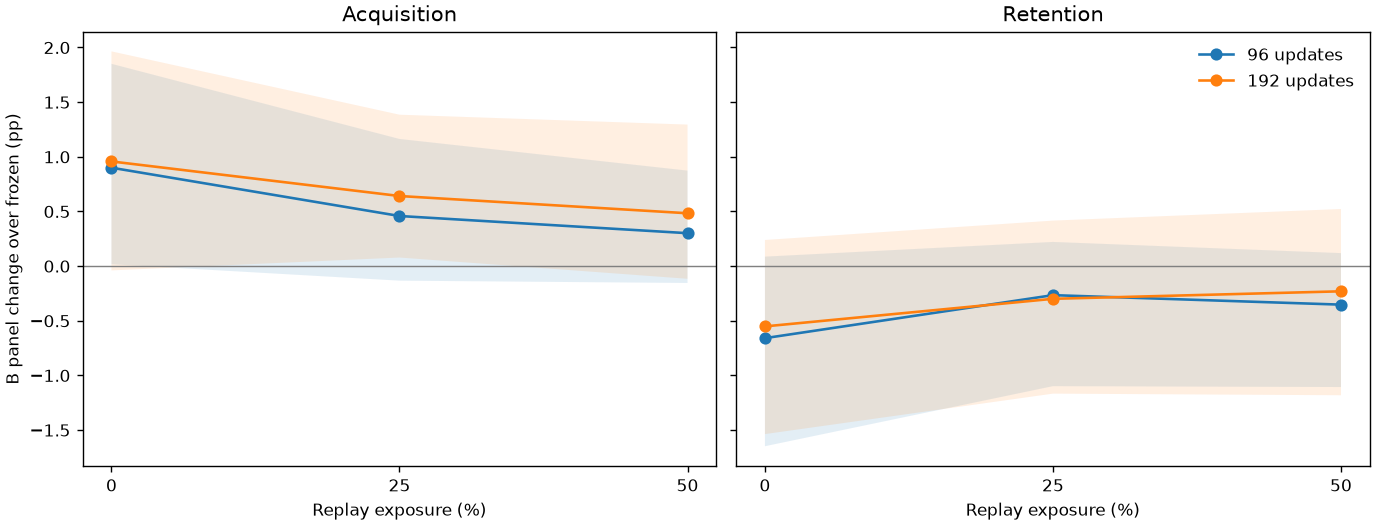